**Innovation Management · A.Y. 2026/27 · Politecnico di Torino** · Tutorial 3, notebook 2 of 2

| | |
|---|---|
| **Goal** | Locate the inventors of a sector on a map, draw the knowledge flows between regions, and test whether citations are more local than we would expect by chance. |
| **Before this** | Notebook 30 (collecting citations), the lecture on knowledge spillovers |
| **Time** | 45 min |
| **PATSTAT environment** | PROD |

← [30 · Collecting patent citations](30_patent_citations.ipynb) &nbsp;|&nbsp; [Back to the README](../README.md)

# Measuring knowledge spillovers

In the lecture we saw that a citation is a **knowledge flow**: the citing inventor builds on the cited patent. A flow becomes a **spillover** when the citing side benefits without paying for it, and patents do not tell us who paid. What they do tell us is **where** the inventors live. If knowledge travelled freely, a citation would land in a region only as often as the region's share of inventors. If citations stay closer to home than that, knowledge leaks locally, and local leaks are the spillovers the theory of agglomeration talks about.

We look at **inventors**, not applicants, because the two addresses tell different stories:

- the **inventor's** address is where the person who made the invention lives, so it is close to where the **R&D was done** and where the knowledge was created;
- the **applicant's** address is where the **owner of the right** sits: often the headquarters, sometimes a holding company chosen for legal or tax reasons. 

Spillovers travel between people who do research, so for this notebook the inventor is the right unit.

So the plan is:

1. take the same sector as in notebook 30, list its applicants, and find where its **inventors** live (`TLS206`, `TLS207`);
2. draw the inventors on a **map** of European regions;
3. draw the **flows**: from the region of the cited inventors to the region of the citing inventors, separately for the citations added by applicants and by examiners;
4. we test: are citations more local than expected? Are applicant citations more local than examiner citations?
5. see whether citations fade with **distance**;
6. see how to use all this in your PW.

### Regions: what NUTS are

To compare places we need regions defined in the same way everywhere. Municipalities are too small and too different (Rome has 2.8 million people, many Alpine villages fewer than 100), countries are too large. The EU solves this with **NUTS**, the *Nomenclature of Territorial Units for Statistics*: a single grid of regions that Eurostat uses for all regional statistics, from GDP to R&D spending.

NUTS has three levels below the country, nested like Russian dolls. Each level is defined by **population**, so **regions of the same level are comparable in size even if their areas are very different**:

| Level | Population | Italy | Switzerland | Number in Europe |
|---|---|---|---|---|
| NUTS 0 | the country | `IT` Italy | `CH` Switzerland | ~40 |
| NUTS 1 | 3-7 million | `ITC` North-West | `CH0` Switzerland | ~100 |
| NUTS 2 | 0.8-3 million | `ITC1` Piemonte | `CH01` Lake Geneva region | ~300 |
| NUTS 3 | 150,000-800,000 | `ITC11` Torino | `CH011` Vaud | ~1,500 |

Three practical things:

- The **code** is built by adding one character to the code of the region above: `ITC11` (Torino) is inside `ITC1` (Piemonte), inside `ITC` (North-West), inside `IT`. So we get the NUTS 2 region of an inventor just by cutting the NUTS 3 code to its first four characters.
- NUTS 2 regions are close to what we call "regions" in everyday language (Piemonte, Lombardia, Bavaria). NUTS 3 are provinces, cantons or *départements*: close to a local labour market, the scale at which people meet and change jobs.
- NUTS cover the EU, plus EFTA countries (Switzerland, Norway...), the UK and candidate countries. The borders are revised every few years (versions 2016, 2021, 2024); we use the **2021** version.

PATSTAT stores the region of each person in `TLS206_PERSON.nuts`, with its level in `nuts_level`. The EPO derives it from the address on the patent, so for an inventor it is the place where they **live**, usually close to where they work. For an inventor in the US or Japan there is no NUTS code, and we only know the country (`person_ctry_code`).

## 1. Setup

We draw maps with **geopandas**, which is pandas plus a column of shapes. If it is missing in your environment, run `%pip install -q geopandas` once and restart the kernel.

In [1]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import FancyArrowPatch, Rectangle
from pathlib import Path
from sqlalchemy import func

from epo.tipdata.patstat import PatstatClient
from epo.tipdata.patstat.database.models import (
    TLS201_APPLN,            # applications
    TLS206_PERSON,           # persons, with their country and NUTS region
    TLS207_PERS_APPLN,       # person <-> application links
    TLS211_PAT_PUBLN,        # publications
    TLS212_CITATION,         # citations
    TLS224_APPLN_CPC,        # CPC classification
)

ENV = "PROD"
patstat = PatstatClient(env=ENV)
db = patstat.orm()
pd.set_option("display.max_colwidth", 60)

### The map of Europe

The region borders come from **Eurostat** ([Nuts2json](https://github.com/eurostat/Nuts2json)): NUTS 2021 regions, simplified for maps at scale 1:10 million. We read four layers: all countries (the grey background, including non-EU countries) and the NUTS regions at levels 0, 2 and 3. If the files are in the `data/nuts2021` folder next to this notebook we read them from there, otherwise we download them.

The coordinates are in the projection **EPSG:3035** (*Lambert azimuthal equal-area*), the official projection of Eurostat for maps of Europe. 

In [2]:
GEO_DIR = Path("data/nuts2021")
GEO_URL = "https://raw.githubusercontent.com/eurostat/Nuts2json/master/pub/v2/2021/3035/10M/{}.json"


def load_layer(name):
    """Read one layer of the Eurostat map, in metres (EPSG:3035)."""
    path = GEO_DIR / f"{name}.json"
    source = path if path.exists() else GEO_URL.format(name)
    layer = gpd.read_file(source)
    # The files are in EPSG:3035 but do not say so: we set the projection by hand
    layer = layer.set_crs(3035, allow_override=True)
    return layer.rename(columns={"id": "nuts_id", "na": "name"})


countries = load_layer("cntrg")      # every country, for the background
nuts0 = load_layer("nutsrg_0")
nuts2 = load_layer("nutsrg_2")
nuts3 = load_layer("nutsrg_3")

print(f"{len(countries)} countries, {len(nuts2)} NUTS 2 regions, {len(nuts3)} NUTS 3 regions")
nuts2.head(3)

74 countries, 327 NUTS 2 regions, 1502 NUTS 3 regions


,nuts_id,name,geometry
0,ES70,Canarias,"MULTIPOLYGON (((2029987 1030471, 2027566 1020378, 201939..."
1,ES64,Ciudad de Melilla,"POLYGON ((3135271 1459427, 3137086 1462455, 3138599 1457..."
2,ES63,Ciudad de Ceuta,"POLYGON ((2929524 1567675, 2931642 1567171, 2933155 1565..."


### A style for all the maps

A good map is mostly about what you leave out. All our maps share the same choices, so we write them once:

- land in light grey, the sea in an even lighter tone, white borders: the background should be quiet;
- one colour scale from pale to dark blue for quantities, **orange** for flows, as in the lecture slides;
- data in **classes** (1, 2-4, 5-9...) rather than a continuous scale, because a few regions have many more inventors than the others and a continuous scale would paint everything else pale;
- title and subtitle on top, aligned left, saying what the reader should see; the source at the bottom.

`new_map` opens an empty map of an area, `add_titles` writes the text, `class_legend` draws the legend of the classes.

In [3]:
NAVY, ORANGE, BLUE, GREY, MID = "#002B49", "#EF7B00", "#4F7CA3", "#4A5A6A", "#8A9AAB"
LAND, LAND_DATA, SEA = "#E3E8ED", "#D5DDE5", "#F4F7F9"
BLUES = LinearSegmentedColormap.from_list("blues", ["#DCE7F0", "#9DB8CF", "#4F7CA3", "#1D4F7A", "#002B49"])
SOURCE = "Source: PATSTAT (EPO TIP). Boundaries: © EuroGeographics, Eurostat Nuts2json (NUTS 2021)."

# Areas to show, as (x min, x max, y min, y max) in metres
EUROPE = (2_600_000, 6_000_000, 1_420_000, 4_650_000)

plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Inter", "Helvetica Neue", "Arial", "DejaVu Sans"]
HALO = [pe.withStroke(linewidth=2.6, foreground="white")]
HEADER, FOOTER = 1.55, 0.35          # inches above and below the map, for titles, legend and source


def new_map(area=EUROPE, width=10.0, side=0.0):
    """An empty map of the area: grey countries on a pale sea. `side` keeps a share of the width free on the right."""
    xmin, xmax, ymin, ymax = area
    map_w = width * (1 - side)
    map_h = map_w * (ymax - ymin) / (xmax - xmin)
    height = map_h + HEADER + FOOTER
    fig = plt.figure(figsize=(width, height))
    ax = fig.add_axes([0, FOOTER / height, 1 - side, map_h / height])
    ax.set_facecolor(SEA)
    countries.plot(ax=ax, color=LAND, edgecolor="white", linewidth=0.7)
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_axis_off()
    ax.add_patch(Rectangle((0, 0), 1, 1, transform=ax.transAxes, color=SEA, zorder=-1))
    return fig, ax


def new_maps(area, n=2, width=14.0, gap=0.15, header=HEADER):
    """n empty maps of the same area side by side, for comparisons."""
    xmin, xmax, ymin, ymax = area
    panel_w = (width - gap * (n - 1)) / n
    map_h = panel_w * (ymax - ymin) / (xmax - xmin)
    height = map_h + header + FOOTER
    fig = plt.figure(figsize=(width, height))
    axes = []
    for i in range(n):
        ax = fig.add_axes([i * (panel_w + gap) / width, FOOTER / height, panel_w / width, map_h / height])
        countries.plot(ax=ax, color=LAND, edgecolor="white", linewidth=0.7)
        ax.set_xlim(xmin, xmax)
        ax.set_ylim(ymin, ymax)
        ax.set_axis_off()
        ax.add_patch(Rectangle((0, 0), 1, 1, transform=ax.transAxes, color=SEA, zorder=-1))
        axes.append(ax)
    return fig, axes


def panel_title(ax, title, subtitle=""):
    """A title written inside the top-left corner of a map panel."""
    ax.text(0.03, 0.97, title, transform=ax.transAxes, ha="left", va="top", fontsize=12, fontweight="bold",
            color=NAVY, path_effects=HALO, zorder=9)
    ax.annotate(subtitle, (0.03, 0.97), xycoords="axes fraction", xytext=(0, -21), textcoords="offset points",
                ha="left", va="top", fontsize=9.5, color=GREY, path_effects=HALO, zorder=9)


def from_top(fig, inches):
    """Vertical position in the figure, `inches` below its top edge."""
    return 1 - inches / fig.get_figheight()


def add_titles(fig, title, subtitle, note=SOURCE):
    fig.text(0.02, from_top(fig, 0.18), title, ha="left", va="top", fontsize=15, fontweight="bold", color=NAVY)
    fig.text(0.02, from_top(fig, 0.52), subtitle, ha="left", va="top", fontsize=10.5, color=GREY)
    fig.text(0.02, 0.1 / fig.get_figheight(), note, ha="left", va="bottom", fontsize=7.5, color=MID)


def fit_area(codes, layer, margin=180_000, aspect=1.2):
    """The smallest area around some regions (inside EUROPE), with a margin and a given width/height."""
    xmin, ymin, xmax, ymax = layer[layer.nuts_id.isin(codes)].total_bounds
    xmin, xmax = max(xmin - margin, EUROPE[0]), min(xmax + margin, EUROPE[1])
    ymin, ymax = max(ymin - margin, EUROPE[2]), min(ymax + margin, EUROPE[3])
    w, h = xmax - xmin, ymax - ymin
    if w / h < aspect:                      # too tall: widen
        extra = (h * aspect - w) / 2
        xmin, xmax = xmin - extra, xmax + extra
    else:                                   # too wide: make taller
        extra = (w / aspect - h) / 2
        ymin, ymax = ymin - extra, ymax + extra
    return (xmin, xmax, ymin, ymax)


def make_classes(values):
    """Round class limits (1, 2, 5, 10, 20, 50...) up to the largest value."""
    steps = [1, 2, 5, 10, 20, 50, 100, 200, 500, 1000, 2000]
    limits = [s for s in steps if s <= values.max()]
    return limits + [np.inf]


def class_labels(limits):
    labels = []
    for lo, hi in zip(limits[:-1], limits[1:]):
        if hi == np.inf:
            labels.append(f"{lo}+")
        elif hi - lo == 1:
            labels.append(f"{lo}")
        else:
            labels.append(f"{lo}-{hi - 1}")
    return labels


def class_legend(fig, limits, title, x=0.02, width=0.42):
    """A horizontal legend under the subtitle, with one coloured box per class."""
    n = len(limits) - 1
    colours = BLUES(np.linspace(0, 1, n))
    h = 0.15 / fig.get_figheight()
    lax = fig.add_axes([x, from_top(fig, 1.17), width, h])
    for i, (colour, label) in enumerate(zip(colours, class_labels(limits))):
        lax.add_patch(Rectangle((i, 0), 0.96, 1, color=colour))
        lax.text(i + 0.48, -0.3, label, ha="center", va="top", fontsize=8, color=GREY)
    lax.text(0, 1.4, title, ha="left", va="bottom", fontsize=8.5, color=GREY)
    lax.set_xlim(0, n)
    lax.set_ylim(0, 1)
    lax.axis("off")
    return colours


def label_regions(ax, regions, column, n=6):
    """Name and value of the n largest regions, to the right of the map point, spread so they do not overlap."""
    x0, x1 = ax.get_xlim()
    y0, y1 = ax.get_ylim()
    chosen = []
    for _, r in regions.sort_values(column, ascending=False).iterrows():
        p = r.geometry.representative_point()
        if x0 < p.x < x1 - 0.2 * (x1 - x0) and y0 < p.y < y1 - 0.03 * (y1 - y0):
            chosen.append((p, r))
        if len(chosen) == n:
            break
    chosen.sort(key=lambda t: -t[0].y)                 # from north to south
    gap, last = 0.035 * (y1 - y0), None
    for p, r in chosen:
        y = p.y if last is None else min(p.y, last - gap)
        last = y
        name = r["name"].split("/")[0].split(",")[0]
        ax.annotate(f"{name}  {r[column]:,.0f}", xy=(p.x, p.y), xytext=(p.x + 0.05 * (x1 - x0), y),
                    va="center", fontsize=8.5, color=NAVY, fontweight="bold", path_effects=HALO, zorder=7,
                    arrowprops=dict(arrowstyle="-", color=NAVY, linewidth=0.6, shrinkA=0, shrinkB=0))
        ax.plot(p.x, p.y, "o", ms=3, color="white", mec=NAVY, mew=1, zorder=8)

### NUTS in a picture

The same piece of Italy at three levels: the country, the NUTS 2 regions, the NUTS 3 provinces. Torino (`ITC11`) is one of the eight provinces of Piemonte (`ITC1`), which is one of the 21 NUTS 2 regions of Italy.

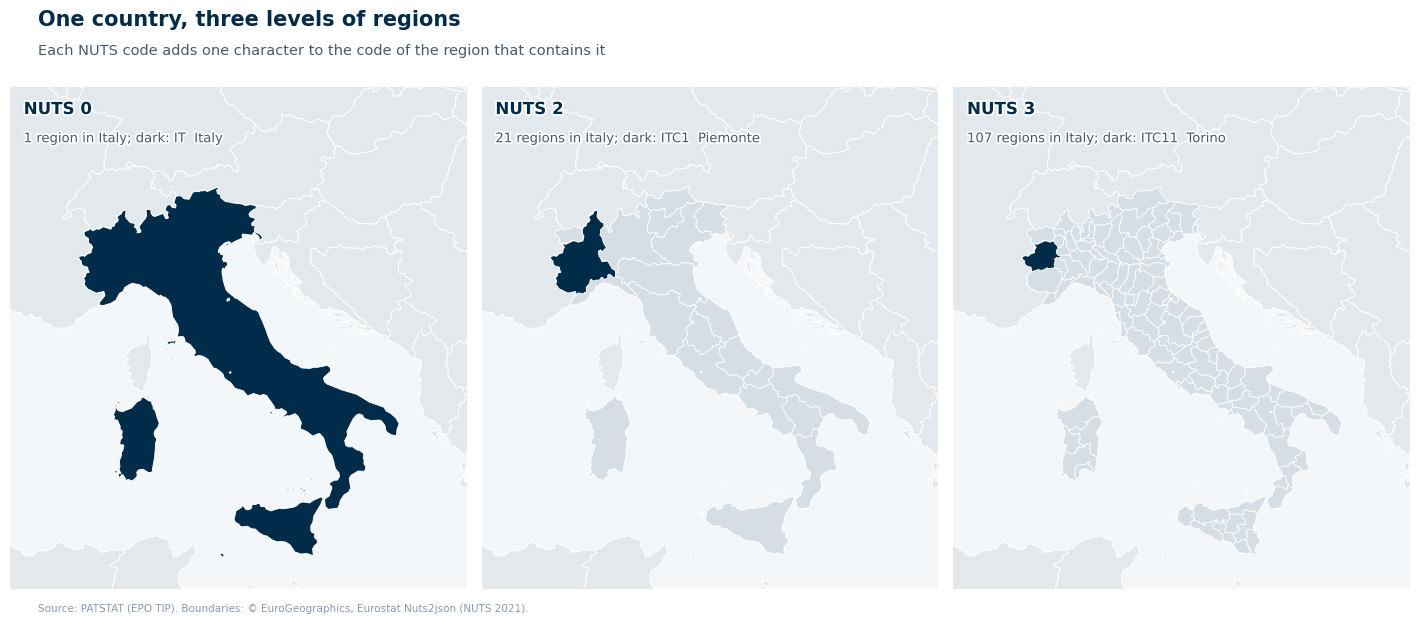

In [4]:
xmin, xmax, ymin, ymax = fit_area(["IT"], nuts0, margin=60_000, aspect=0.9)
ITALY = (xmin - 120_000, xmax + 120_000, ymin, ymax + 250_000)     # room on top for the panel titles
fig, axes = new_maps(ITALY, n=3, width=14, header=0.95)
levels = [(nuts0, "IT", "NUTS 0", "IT  Italy"), (nuts2, "ITC1", "NUTS 2", "ITC1  Piemonte"), (nuts3, "ITC11", "NUTS 3", "ITC11  Torino")]
for ax, (layer, code_, level, label) in zip(axes, levels):
    italy = layer[layer.nuts_id.str.startswith("IT")]
    italy.plot(ax=ax, color=LAND_DATA, edgecolor="white", linewidth=0.6)
    italy[italy.nuts_id == code_].plot(ax=ax, color=NAVY, edgecolor="white", linewidth=0.6)
    panel_title(ax, level, f"{len(italy)} region{'s' if len(italy) > 1 else ''} in Italy; dark: {label}")
add_titles(fig, "One country, three levels of regions",
           "Each NUTS code adds one character to the code of the region that contains it")
plt.show()

## 2. The sample: same sector as notebook 30 (coffee capsules)

We rebuild the sample of notebook 30: EP applications in **coffee capsules and pods** (CPC `B65D 85/804`), filed 2000-2022. Every query below keeps only these applications through `in_sample`.

In [5]:
CPC_PREFIX = "B65D85/804"    # coffee capsules and pods; change it to your PW sector :)
YEARS = (2000, 2022)

symbol = func.replace(TLS224_APPLN_CPC.cpc_class_symbol, " ", "")
q = (
    db.query(TLS201_APPLN.appln_id, TLS201_APPLN.docdb_family_id, TLS201_APPLN.appln_filing_year)
    .join(TLS224_APPLN_CPC, TLS224_APPLN_CPC.appln_id == TLS201_APPLN.appln_id)
    .filter(symbol.like(CPC_PREFIX + "%"))
    .filter(TLS201_APPLN.appln_auth == "EP")
    .filter(TLS201_APPLN.appln_filing_year.between(*YEARS))
    .distinct()
)
ep = patstat.df(q)
SAMPLE = [int(i) for i in ep.appln_id]


def in_sample(query, appln_id_col):
    """Keep only the applications of our sample."""
    return query.filter(appln_id_col.in_(SAMPLE))


print(f"Our sample: {len(SAMPLE):,} EP applications filed {YEARS[0]}-{YEARS[1]}")

Our sample: 1,410 EP applications filed 2000-2022


### Who files in this sector?

As in notebook 30, we read the applicants of each application: the persons with `applt_seq_nr > 0` in `TLS207_PERS_APPLN`, with their harmonised name `psn_name` and their country from `TLS206_PERSON`. The table counts the applications of each applicant.

In [6]:
q = in_sample(
    db.query(TLS207_PERS_APPLN.appln_id, TLS207_PERS_APPLN.applt_seq_nr,
             TLS206_PERSON.psn_name, TLS206_PERSON.person_ctry_code)
    .join(TLS206_PERSON, TLS206_PERSON.person_id == TLS207_PERS_APPLN.person_id)
    .filter(TLS207_PERS_APPLN.applt_seq_nr > 0),
    TLS207_PERS_APPLN.appln_id,
)
applicants = patstat.df(q).drop_duplicates(["appln_id", "psn_name"])

top_applicants = (applicants.groupby("psn_name")
                            .agg(applications=("appln_id", "nunique"),
                                 country=("person_ctry_code", lambda s: s.mode().iat[0]))
                            .sort_values("applications", ascending=False))
top_applicants.head(10)

,applications,country
psn_name,,
NESTEC,144,CH
KONINKLIJKE DOUWE EGBERTS,128,NL
NESTLE,126,CH
K-FEE SYSTEM,52,DE
KRAFT FOODS R & D,36,US
FREEZIO,30,CH
LUIGI LAVAZZA,28,IT
DELICA,26,CH
TCHIBO,21,DE


## 3. Where do the inventors live? (`TLS207` → `TLS206`)

Persons live in two tables. `TLS206_PERSON` has one row per person (applicant or inventor), with name, address, country and NUTS region. `TLS207_PERS_APPLN` links persons to applications and says in which role:

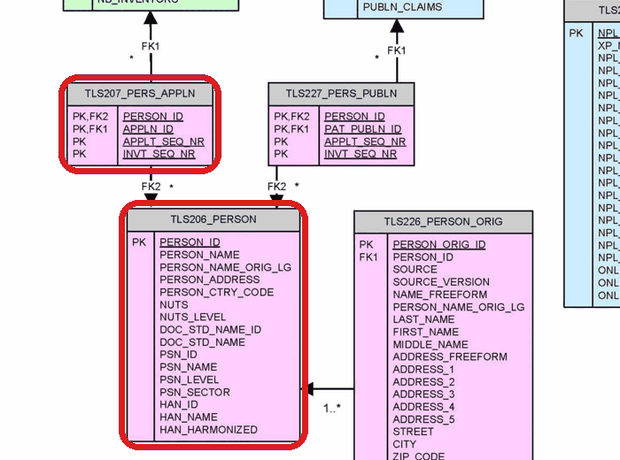

*TLS207_PERS_APPLN links each person to each application; TLS206_PERSON describes the person, including `person_ctry_code`, `nuts` and `nuts_level`.*

| Attribute | Table | Meaning |
|---|---|---|
| `person_id`, `appln_id` | TLS207 | Which person, which application. |
| `applt_seq_nr` | TLS207 | Position of the person among the **applicants** (1 = first applicant); 0 if the person is not an applicant. |
| `invt_seq_nr` | TLS207 | Position of the person among the **inventors** (1 = first inventor); 0 if the person is not an inventor. |
| `person_ctry_code` | TLS206 | Country of the address, e.g. `CH`, `IT`, `US`. |
| `nuts` | TLS206 | NUTS code of the address, e.g. `CH011`. |
| `nuts_level` | TLS206 | Level of that code: 3 for a full NUTS 3 code, lower (0-2) if the address was only matched to a larger region, **4** if the code was added from the OECD **REGPAT** database (it is then a normal NUTS code), 9 if no region could be assigned. |

A person is an **inventor** of an application when `invt_seq_nr > 0`, and an applicant when `applt_seq_nr > 0`; one person can be both (an individual inventor who files alone). We join the two tables and keep the inventors.

We write the query as a function, because we will need it twice: for the applications of our sample (the citing side) and for the applications they cite.

### Why the NUTS code is often missing, and what we do about it

The NUTS code is computed from the **address** of the inventor. The country (`person_ctry_code`) is almost always there, but the full address is not, so a person can have a European country and no NUTS code. Two cases are frequent:

1. **National publications without addresses.** Many applications we cite are German, French, British or Swiss national patents, often old ones. Their publications frequently give the inventor's name and country but no street address, so PATSTAT cannot place them in a region (`nuts_level` 0 = country only, 9 = no region).
2. **Older NUTS versions.** NUTS borders change every few years (2010, 2013, 2016, 2021, 2024). A few persons carry a code of another version, such as `FR222` (Oise in the 2013 version, `FRE22` since 2016). These codes are not in our 2021 map.

Watch out for a trap: `nuts_level` is not always the level of the code. PATSTAT completed many addresses with the regions of the OECD **REGPAT** database, and marks those records with `nuts_level = 4`, even if the code itself is an ordinary NUTS 3 code like `CH011`. So we do not filter on `nuts_level`: we read the level from the **length of the code** (2 characters = country, 4 = NUTS 2, 5 = NUTS 3).

The fixes:

1. **Borrow from the family.** The same invention is usually filed at several offices (the DOCDB family of Tutorial 1), with the same inventors. If the application itself has no located inventor, we take the inventors of the **family member** with the most located inventors: often the EP or the WO application, which always print the full address.
2. **Drop old codes.** They are few, so we treat them as missing. This way every section of the notebook (maps, shares, distances) uses exactly the same citations.
3. **Extract/infer NUTS from address directly**: NER to extract the components + Google correction + coordinates = NUTS

In [8]:
def inventors_of(appln_ids):
    """One row per inventor of each application, with country and NUTS region (2021 map).

    If the application itself has no inventor with a NUTS code, we use the family member
    with the most inventors with a NUTS code."""
    # Step 1: the DOCDB family (and the office) of each application
    q = (db.query(TLS201_APPLN.appln_id, TLS201_APPLN.docdb_family_id, TLS201_APPLN.appln_auth)
         .filter(TLS201_APPLN.appln_id.in_(appln_ids)))
    fam = patstat.df(q)
    FAMILIES = [int(f) for f in fam.docdb_family_id.unique()]

    # Step 2: the inventors of every application of these families
    q = (
        db.query(
            TLS201_APPLN.docdb_family_id,
            TLS201_APPLN.appln_id.label("member_id"),
            TLS207_PERS_APPLN.invt_seq_nr,
            TLS206_PERSON.person_id,
            TLS206_PERSON.person_ctry_code,
            TLS206_PERSON.nuts,
            TLS206_PERSON.nuts_level,
        )
        .join(TLS207_PERS_APPLN, TLS207_PERS_APPLN.appln_id == TLS201_APPLN.appln_id)
        .join(TLS206_PERSON, TLS206_PERSON.person_id == TLS207_PERS_APPLN.person_id)
        .filter(TLS207_PERS_APPLN.invt_seq_nr > 0)
        .filter(TLS201_APPLN.docdb_family_id.in_(FAMILIES))
    )
    inv = fam.merge(patstat.df(q), on="docdb_family_id")

    # The three levels we use: country, NUTS 2 and NUTS 3.
    # The level is read from the length of the code (nuts_level = 4 marks codes taken from REGPAT);
    # codes that are not in our 2021 map (other NUTS versions) are treated as missing.
    inv["ctry"] = inv.person_ctry_code.str.strip().replace("", np.nan)
    code = inv.nuts.str.strip()
    inv["nuts2"] = code.str[:4].where(code.str.len() >= 4)
    inv["nuts2"] = inv.nuts2.where(inv.nuts2.isin(nuts2.nuts_id))
    inv["nuts3"] = code.where(code.isin(nuts3.nuts_id))

    # Step 3: for each application keep one member: the one with most located inventors (itself if tied)
    inv["itself"] = inv.member_id == inv.appln_id
    best = (inv.assign(located=inv.nuts2.notna())
               .groupby(["appln_id", "member_id"]).agg(located=("located", "sum"), itself=("itself", "max"))
               .reset_index()
               .sort_values(["appln_id", "located", "itself"], ascending=[True, False, False])
               .drop_duplicates("appln_id"))
    return inv.merge(best[["appln_id", "member_id"]], on=["appln_id", "member_id"])


inv = inventors_of(SAMPLE)
print(f"{len(inv):,} inventor rows, {inv.person_id.nunique():,} different inventors")
print(f"Applications whose inventors come from another family member: {(~inv.drop_duplicates('appln_id').itself).sum():,}")
inv.head()
##itself: it checks whether the inventor information comes from the same 

3,893 inventor rows, 2,304 different inventors
Applications whose inventors come from another family member: 63


,appln_id,docdb_family_id,appln_auth,member_id,invt_seq_nr,person_id,person_ctry_code,nuts,nuts_level,ctry,nuts2,nuts3,itself
0,439203932,50733201,EP,439203932,3,54619205,IT,ITH53,3,IT,ITH5,ITH53,True
1,439203932,50733201,EP,439203932,1,44818349,IT,ITH53,3,IT,ITH5,ITH53,True
2,439203932,50733201,EP,439203932,2,55676118,IT,ITH53,3,IT,ITH5,ITH53,True
3,439203932,50733201,EP,439203932,4,48065853,IT,ITH54,3,IT,ITH5,ITH54,True
4,415659018,51263951,EP,415659018,1,45053341,DE,DEA2B,3,DE,DEA2,DEA2B,True


How complete is the information? The country is almost always there. The NUTS code exists only for inventors in Europe, so we measure its coverage among them.

In [9]:
EUROPE_CTRY = set(nuts0.nuts_id) | {"GB", "GR"}     # NUTS writes UK and EL, PATSTAT GB and GR
in_europe = inv[inv.ctry.isin(EUROPE_CTRY)]

print(f"Inventors with a country:            {inv.ctry.notna().mean():.0%}")
print(f"Inventors living in Europe:          {len(in_europe) / len(inv):.0%}")
print(f"  of which with a NUTS 3 code:       {in_europe.nuts3.notna().mean():.0%}")

raw = inv.nuts.str.strip()
old = raw[(raw.str.len() == 5) & ~raw.isin(nuts3.nuts_id)]
print(f"Codes of other NUTS versions (dropped): {len(old):,} inventor rows  {sorted(set(old))[:8]}")

print("\nnuts_level of the European inventors (4 = code taken from REGPAT):")
print(in_europe.nuts_level.value_counts().to_string())
inv.ctry.value_counts().head(10)

Inventors with a country:            100%
Inventors living in Europe:          83%
  of which with a NUTS 3 code:       93%
Codes of other NUTS versions (dropped): 236 inventor rows  ['ES705', 'FR222', 'FR231', 'FR261', 'FR263', 'FR411', 'FR414', 'FR431']

nuts_level of the European inventors (4 = code taken from REGPAT):
nuts_level
3    2343
4     869
0       5


ctry
CH    961
NL    547
US    513
GB    453
IT    434
DE    398
FR    246
ES     60
CA     36
PT     36
Name: count, dtype: int64

The European inventors still without a NUTS code are those whose address is unknown in every member of the family, plus the few with a code of another NUTS version.

### One region per application

An application often has several inventors, sometimes in different regions. To compare citing and cited applications we need **one** location per application. We take the region where **most** of its inventors live; with a tie, the region of the first inventor. We do it separately for each level.

In [10]:
LEVELS = ["ctry", "nuts2", "nuts3"]


def main_region(inv, level):
    """For each application, the region of the largest number of its inventors."""
    x = inv.dropna(subset=[level])
    counts = (x.groupby(["appln_id", level])
                .agg(n=("person_id", "size"), first=("invt_seq_nr", "min"))
                .reset_index()
                .sort_values(["appln_id", "n", "first"], ascending=[True, False, True]))
    return counts.drop_duplicates("appln_id").set_index("appln_id")[level]


def locate(inv):
    return pd.DataFrame({level: main_region(inv, level) for level in LEVELS})


loc = locate(inv)
ep_loc = ep.set_index("appln_id").join(loc)
ep_loc[LEVELS].notna().mean().rename("share of applications located").to_frame()

,share of applications located
ctry,0.997163
nuts2,0.847518
nuts3,0.842553


### Applicant address vs inventor address

For the main applicants, compare the country of the applicant with the region where their inventors work. When the two differ, the patent is owned in one place and invented in another, and only the second one matters for spillovers.

In [12]:
first = applicants[applicants.applt_seq_nr == 1].drop_duplicates("appln_id").set_index("appln_id")
both = first.join(loc, how="inner")
names2 = nuts2.set_index("nuts_id").name

rows = []
for firm in top_applicants.index[:8]:
    apps = both[both.psn_name == firm]
    regions_ = apps.nuts2.value_counts(normalize=True)
    main = regions_.index[0] if len(regions_) else None
    rows.append({"applicant": firm, "applicant country": top_applicants.loc[firm, "country"],
                 "applications": len(apps),
                 "inventor countries": ", ".join(apps.ctry.value_counts().index[:3]),
                 "main inventor region": f"{main} {names2.get(main, '')}" if main else "-",
                 "share in that region": regions_.iloc[0] if len(regions_) else np.nan})
pd.DataFrame(rows).style.format({"share in that region": "{:.0%}"}).hide(axis="index")
#share in that region is the share of applications invented in the applicant top region 

applicant,applicant country,applications,inventor countries,main inventor region,share in that region
NESTEC,CH,144,"CH, FR, US",CH01 Région lémanique,91%
KONINKLIJKE DOUWE EGBERTS,NL,128,"NL, GB, DE",NL31 Utrecht,58%
NESTLE,CH,126,"CH, FR, IT",CH01 Région lémanique,75%
K-FEE SYSTEM,DE,52,"DE, CH",DEA2 Köln,87%
KRAFT FOODS R & D,US,36,"GB, US, DE","UKJ1 Berkshire, Buckinghamshire and Oxfordshire",77%
FREEZIO,CH,30,"DE, CH",DEA2 Köln,83%
LUIGI LAVAZZA,IT,28,"IT, GB",ITC1 Piemonte,86%
DELICA,CH,26,CH,CH03 Nordwestschweiz,46%


## 4. Map 1: where the inventors of the sector live

We count, for each NUTS 2 region, the applications with **at least one inventor** living there. An application with inventors in Lausanne and Milan counts once for each region, so the sum over regions is larger than the number of applications.

The map is next to a ranking of the top regions: the map shows *where*, the bars show *how much*, and reading numbers off colours is hard.

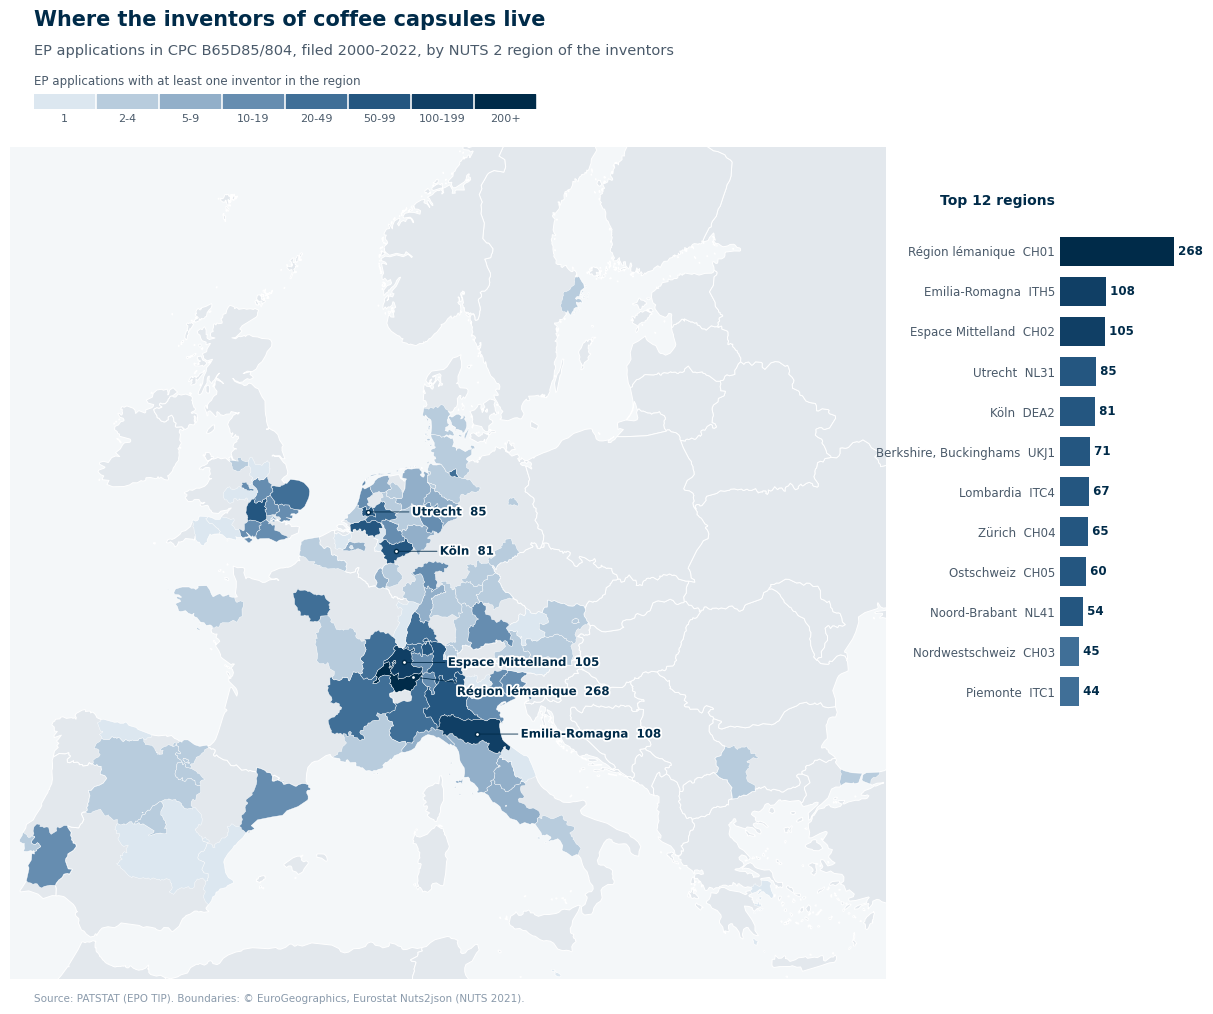

In [13]:
per_region = (inv.dropna(subset=["nuts2"])
                 .drop_duplicates(["appln_id", "nuts2"])
                 .groupby("nuts2").size().rename("applications"))
regions = nuts2.merge(per_region, left_on="nuts_id", right_index=True, how="left")
regions["applications"] = regions.applications.fillna(0)
with_data = regions[regions.applications > 0].copy()

limits = make_classes(with_data.applications)
with_data["class"] = pd.cut(with_data.applications, limits, right=False, labels=False)

# Map on the left, ranking of the top regions on the right
fig, ax = new_map(EUROPE, width=12, side=0.27)
colours = class_legend(fig, limits, "EP applications with at least one inventor in the region")
with_data.plot(ax=ax, color=[colours[c] for c in with_data["class"]], edgecolor="white", linewidth=0.3)
label_regions(ax, with_data, "applications", n=5)

ranking = with_data.nlargest(12, "applications").iloc[::-1]
map_box = ax.get_position()
bx = fig.add_axes([0.875, map_box.y0 + 0.30 * map_box.height, 0.10, 0.62 * map_box.height])
bx.barh(range(len(ranking)), ranking.applications, color=[colours[c] for c in ranking["class"]], height=0.72)
bx.set_yticks(range(len(ranking)))
bx.set_yticklabels([f"{n.split('/')[0][:22]}  {c}" for n, c in zip(ranking.name, ranking.nuts_id)], fontsize=8.5, color=GREY)
for i, v in enumerate(ranking.applications):
    bx.text(v, i, f" {v:,.0f}", va="center", fontsize=8.5, color=NAVY, fontweight="bold")
bx.tick_params(length=0)
bx.set_xticks([])
for side in bx.spines.values():
    side.set_visible(False)
bx.set_title("Top 12 regions", loc="left", fontsize=10, color=NAVY, fontweight="bold", x=-1.0)

add_titles(fig, "Where the inventors of coffee capsules live",
           f"EP applications in CPC {CPC_PREFIX}, filed {YEARS[0]}-{YEARS[1]}, by NUTS 2 region of the inventors")
plt.show()

### Who is behind each region?

A region is on the map because some firms have inventors there. The function below lists, for any region, the first applicants of the applications invented there. We call it for the top 12 regions; you can call it for any NUTS 2 code you are curious about, for example `who_invents(["PT18"])`.

In [14]:
first_applicant = applicants[applicants.applt_seq_nr == 1].drop_duplicates("appln_id").set_index("appln_id").psn_name
in_region = inv.dropna(subset=["nuts2"]).drop_duplicates(["appln_id", "nuts2"])


def who_invents(regions, n_firms=3):
    """For each NUTS 2 region: applications invented there and their main applicants."""
    rows = []
    for r in regions:
        apps = in_region[in_region.nuts2 == r].appln_id
        firms = apps.map(first_applicant).value_counts()
        rows.append({"region": f"{r} {names2.get(r, '')}", "applications": len(apps),
                     "main applicants": ", ".join(f"{f} ({k})" for f, k in firms.head(n_firms).items())})
    return pd.DataFrame(rows).style.hide(axis="index")


who_invents(per_region.nlargest(12).index)

region,applications,main applicants
CH01 Région lémanique,268,"NESTEC (134), NESTLE (110), ETHICAL COFFEE COMPANY (7)"
ITH5 Emilia-Romagna,108,"CAFFITALY SYSTEM (16), SARONG (15), MACCHIAVELLI (10)"
CH02 Espace Mittelland,105,"NESTEC (41), NESTLE (35), DELICA (12)"
NL31 Utrecht,85,"KONINKLIJKE DOUWE EGBERTS (77), SARA LEE/DE (5), APIQE HOLDINGS (3)"
DEA2 Köln,81,"K-FEE SYSTEM (46), FREEZIO (25), GCS German Capsule Solution GmbH (4)"
"UKJ1 Berkshire, Buckinghamshire and Oxfordshire",71,"KONINKLIJKE DOUWE EGBERTS (33), KRAFT FOODS R & D (31), MARS (4)"
ITC4 Lombardia,67,"TUTTOESPRESSO (20), GOGLIO (7), IMPER (7)"
CH04 Zürich,65,"DELICA (12), QBO COFFEE (11), LUNA TECHNOLOGY SYSTEMS LTS (8)"
CH05 Ostschweiz,60,"FREEZIO (27), NESTEC (15), MUHLEMANN IP (4)"
NL41 Noord-Brabant,54,"KONINKLIJKE DOUWE EGBERTS (28), PHILIPS ELECTRONICS (10), STAS I.P. (4)"


Inventive activity is very concentrated: a handful of regions hold most applications, and most of Europe holds none.

### Why the Lake Geneva region, and Vaud in particular?

With real PATSTAT data the first region is the **Lake Geneva region** (`CH01`), and inside it the canton of **Vaud** (`CH011`). The reason is one firm. The capsule system was born at Nestlé, which has built most of its coffee R&D and its whole Nespresso chain in a few kilometres of Vaud:

- **Vevey**: the world headquarters of Nestlé. **Lausanne**: the headquarters of Nespresso and Nestlé's central research centre.
- **Orbe**: the Nestlé **Product Technology Centre** for coffee (since 1959), and since 2013 the **System Technology Centre**, where the capsules and machines of Nespresso and Nescafé Dolce Gusto are designed.
- **Orbe** (2002) and **Avenches** (2008): the first two Nespresso production centres. The third one (2015) is in **Romont**, just across the border in the canton of Fribourg, which is why Fribourg (`CH022`) also shows up.

So the engineers who write capsule patents live around the places where Nestlé does capsule R&D. This is the agglomeration story of the lecture seen from the data: once the leading firm is there, suppliers, machine makers, specialised engineers and competitors' engineers have reasons to be close too. The same logic explains the second group of hubs, the Italian roasters and capsule makers (Lavazza in Turin, illy in Trieste, the packaging firms of Emilia-Romagna and Lombardy).

The question for the rest of the notebook is whether the knowledge created in Vaud **stays** in Vaud more than the location of inventors alone would predict.

Let us first zoom on the densest area, at the finer NUTS 3 level.

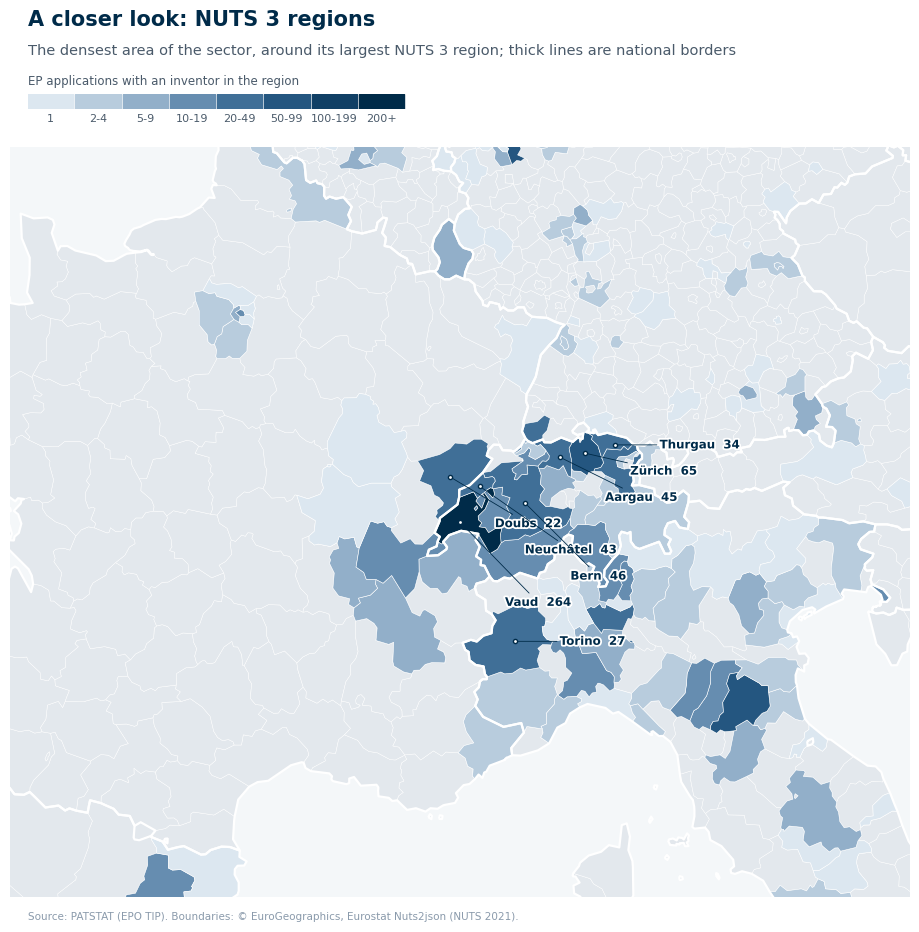

In [15]:
per_region3 = (inv.dropna(subset=["nuts3"])
                  .drop_duplicates(["appln_id", "nuts3"])
                  .groupby("nuts3").size().rename("applications"))
regions3 = nuts3.merge(per_region3, left_on="nuts_id", right_index=True, how="inner")

# Centre the zoom on the NUTS 3 region with most applications, about 500 km around it
centre = regions3.loc[regions3.applications.idxmax()].geometry.representative_point()
R = 500_000
ZOOM = (centre.x - 1.2 * R, centre.x + 1.2 * R, centre.y - R, centre.y + R)

limits3 = make_classes(regions3.applications)
regions3["class"] = pd.cut(regions3.applications, limits3, right=False, labels=False)

fig, ax = new_map(ZOOM, width=9)
colours3 = class_legend(fig, limits3, "EP applications with an inventor in the region")
nuts3.plot(ax=ax, color=LAND, edgecolor="white", linewidth=0.35)
regions3.plot(ax=ax, color=[colours3[c] for c in regions3["class"]], edgecolor="white", linewidth=0.4)
nuts0.boundary.plot(ax=ax, color="white", linewidth=1.6)
label_regions(ax, regions3, "applications", n=8)
add_titles(fig, "A closer look: NUTS 3 regions", "The densest area of the sector, around its largest NUTS 3 region; thick lines are national borders")
plt.show()

## 5. The citations, with their two ends located

We collect the backward citations of the sample as in notebook 30, in two steps: first the publications of our applications (`TLS211`), then the patents they cite (`TLS212`), brought back to the cited application (`TLS211` again). We also keep the filing year of the cited application.

We drop:
- citations to **artificial** publications (`pat_publn_id` from 900,000,000), whose application is unknown;
- citations inside the **same family**: these are the same invention, not a flow between two inventions.

In [16]:
# Step 1: the publications of our applications
q = in_sample(db.query(TLS211_PAT_PUBLN.appln_id, TLS211_PAT_PUBLN.pat_publn_id), TLS211_PAT_PUBLN.appln_id)
pubs = patstat.df(q)
PUBS = [int(i) for i in pubs.pat_publn_id]

# Step 2: the patent publications they cite
q = (
    db.query(TLS212_CITATION.pat_publn_id, TLS212_CITATION.cited_pat_publn_id, TLS212_CITATION.citn_origin)
    .filter(TLS212_CITATION.pat_publn_id.in_(PUBS))
    .filter(TLS212_CITATION.cited_pat_publn_id > 0)
    .filter(TLS212_CITATION.cited_pat_publn_id < 900_000_000)
)
cit = patstat.df(q)

# Step 3: the cited application, its family and filing year
CITED_PUBS = [int(i) for i in cit.cited_pat_publn_id.unique()]
q = (
    db.query(
        TLS211_PAT_PUBLN.pat_publn_id.label("cited_pat_publn_id"),
        TLS201_APPLN.appln_id.label("cited_appln_id"),
        TLS201_APPLN.docdb_family_id.label("cited_family"),
        TLS201_APPLN.appln_filing_year.label("cited_year"),
    )
    .join(TLS201_APPLN, TLS201_APPLN.appln_id == TLS211_PAT_PUBLN.appln_id)
    .filter(TLS211_PAT_PUBLN.pat_publn_id.in_(CITED_PUBS))
)
cited = patstat.df(q)

cit = (cit.merge(pubs, on="pat_publn_id")
          .merge(cited, on="cited_pat_publn_id")
          .merge(ep.rename(columns={"appln_filing_year": "citing_year", "docdb_family_id": "citing_family"}),
                 on="appln_id"))
cit = cit[(cit.citing_family != cit.cited_family) & (cit.cited_year < 9999)]
cit.head()

,pat_publn_id,cited_pat_publn_id,citn_origin,appln_id,cited_appln_id,cited_family,cited_year,citing_family,citing_year
0,512121566,56672370,APP,481953842,55748224,36650897,2006,56557519,2017
1,602874629,337804035,FOP,548055097,334690652,43036954,2011,69953877,2021
2,572493985,277400516,SEA,534638236,39478336,39693316,2006,71521650,2020
3,479810897,55679169,APP,474263941,55491229,38234701,2008,44925548,2011
4,557633622,331602814,APP,549460323,331521444,43527273,2009,48626565,2014


Each row of `cit` is one **publication** of ours citing one **publication** of another patent. That is too fine for us: the same link between two inventions can appear in several rows, because

- our A1 and our B1 can both cite it,
- the applicant and the examiner can both cite it,
- we can cite two publications (A1 and B1) of the same cited application.

What we want is the link between two **applications**: "application X of our sample cites application Y". So we keep **one row per pair** (citing application, cited application), and we call each pair **one citation**. We also remember who added it:

- `applicant` if the applicant cited it (`citn_origin = "APP"`), even if the examiner cited it too;
- `examiner` if only the search or examination added it (`SEA`, `ISR`, `EXA`, ...).

In [17]:
pairs = (cit.groupby(["appln_id", "cited_appln_id"])
            .agg(citing_year=("citing_year", "first"),
                 cited_year=("cited_year", "first"),
                 by_applicant=("citn_origin", lambda s: (s == "APP").any()))
            .reset_index())
pairs["origin"] = np.where(pairs.by_applicant, "applicant", "examiner")

print(f"Rows in cit (publication cites publication):    {len(cit):6,}")
print(f"Citations (application cites application):      {len(pairs):6,}")
print(f"  made by {pairs.appln_id.nunique():,} of the {len(SAMPLE):,} applications of our sample")
print(f"  to {pairs.cited_appln_id.nunique():,} different cited applications")
print(f"  on average {len(pairs) / pairs.appln_id.nunique():.1f} citations per citing application")
pairs.origin.value_counts().rename("citations")

Rows in cit (publication cites publication):    12,697
Citations (application cites application):      11,097
  made by 1,408 of the 1,410 applications of our sample
  to 4,466 different cited applications
  on average 7.9 citations per citing application


origin
examiner     7628
applicant    3469
Name: citations, dtype: int64

How to read these numbers: some applications of the sample do not appear among the citing ones because they cite no patent (only scientific literature, or only patents of their own family, which we dropped). The cited applications can be anywhere in the world and in any technology, and each of our applications cites several of them, so there are more cited than citing applications.

Now we locate the **inventors** of the cited applications with the same function, family borrowing included, and put the two sides next to each other: one row per citation, with the region of the citing inventors (`_citing`) and of the cited inventors (`_cited`).

In [18]:
CITED_APPS = [int(i) for i in pairs.cited_appln_id.unique()]
inv_cited = inventors_of(CITED_APPS)
loc_cited = locate(inv_cited)

cites = (pairs
         .join(loc.add_suffix("_citing"), on="appln_id")
         .join(loc_cited.add_suffix("_cited"), on="cited_appln_id"))
cites

,appln_id,cited_appln_id,citing_year,cited_year,by_applicant,origin,ctry_citing,nuts2_citing,nuts3_citing,ctry_cited,nuts2_cited,nuts3_cited
0,940,20295489,2007,1987,False,examiner,CH,CH07,CH070,NaN,NaN,NaN
1,940,22640145,2007,1968,False,examiner,CH,CH07,CH070,NaN,NaN,NaN
2,940,24033469,2007,2004,False,examiner,CH,CH07,CH070,IT,NaN,NaN
3,940,47699043,2007,2002,False,examiner,CH,CH07,CH070,US,NaN,NaN
4,18384,23113966,2003,1993,False,examiner,KR,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
11092,634865117,405681638,2021,2013,False,examiner,NL,NL22,NL221,IT,ITH5,ITH53
11093,634865117,447321123,2021,2015,True,applicant,NL,NL22,NL221,NL,NL31,NL310
11094,634865117,471638040,2021,2016,False,examiner,NL,NL22,NL221,IT,ITH5,ITH53
11095,634865117,474944580,2021,2017,False,examiner,NL,NL22,NL221,CH,CH02,CH024


How many cited applications can we place on the map? The table below splits them by the **office** of the cited application. Inventors outside Europe can never have a NUTS code, so we look only at cited applications whose inventors live in a European country. The last column shows how many of those needed the family to be located: without it they would be missing.

In [19]:
cited_info = (inv_cited.drop_duplicates("appln_id").set_index("appln_id")[["appln_auth", "itself"]]
                       .join(loc_cited))
european = cited_info[cited_info.ctry.isin(EUROPE_CTRY)]
coverage = (european.groupby("appln_auth")
                    .agg(cited_applications=("ctry", "size"),
                         with_nuts2=("nuts2", lambda s: s.notna().mean()),
                         located_through_family=("itself", lambda s: (~s).mean()))
                    .sort_values("cited_applications", ascending=False))
print(f"Cited applications with inventors in Europe: {len(european):,}; "
      f"with a NUTS 2 region: {european.nuts2.notna().mean():.0%}")
coverage.head(10).style.format({"with_nuts2": "{:.0%}", "located_through_family": "{:.0%}"})

Cited applications with inventors in Europe: 2,594; with a NUTS 2 region: 82%


,cited_applications,with_nuts2,located_through_family
appln_auth,,,
WO,1066,85%,85%
EP,680,97%,2%
US,484,79%,78%
DE,158,53%,57%
GB,61,46%,49%
FR,31,19%,26%
ES,30,60%,60%
CH,18,22%,22%
CA,13,100%,100%


## 6. Map 2: knowledge flows between regions

Each citation is a flow **from** the region of the cited inventors **to** the region of the citing inventors: knowledge travels from the older patent to the newer one. We draw:

- an **arc** for each pair of different regions, thicker and darker when there are more citations, with the arrow pointing at the citing region;
- a **circle** for citations where the citing and the cited inventors live in the **same region**, larger when there are more.

We draw two maps side by side, with the same scale:

- **left**, the citations added by **applicants**: the inventors knew these patents, so they are the closest thing to a real flow of knowledge between people;
- **right**, the citations added by **examiners** during the search: the examiner found them in a database, and the inventor may never have read them.

If knowledge spreads through people who meet, work together and change jobs, the applicant map should be more **local** (more ink in circles and short arcs) than the examiner map. Examiners search the whole world's patents from their desk, so for them distance should not matter.

In [20]:
points2 = nuts2.set_index("nuts_id").representative_point()   # a point inside each region
x0, x1, y0, y1 = EUROPE
points2 = points2[points2.x.between(x0, x1) & points2.y.between(y0, y1)]   # drop overseas regions


def region_flows(origin):
    """Number of citations between each pair of NUTS 2 regions (cited -> citing), for one origin."""
    f = (cites[cites.origin == origin]
         .dropna(subset=["nuts2_citing", "nuts2_cited"])
         .groupby(["nuts2_cited", "nuts2_citing"]).size().rename("n").reset_index())
    return f[f.nuts2_cited.isin(points2.index) & f.nuts2_citing.isin(points2.index)]


flows_by = {origin: region_flows(origin) for origin in ["applicant", "examiner"]}
for origin, f in flows_by.items():
    inside = f.loc[f.nuts2_cited == f.nuts2_citing, "n"].sum()
    print(f"{origin:10s}: {f.n.sum():5,} citations with both inventors located; "
          f"in {inside / f.n.sum():.0%} of them citing and cited inventors live in the same NUTS 2 region")

applicant : 2,159 citations with both inventors located; in 39% of them citing and cited inventors live in the same NUTS 2 region
examiner  : 3,986 citations with both inventors located; in 17% of them citing and cited inventors live in the same NUTS 2 region


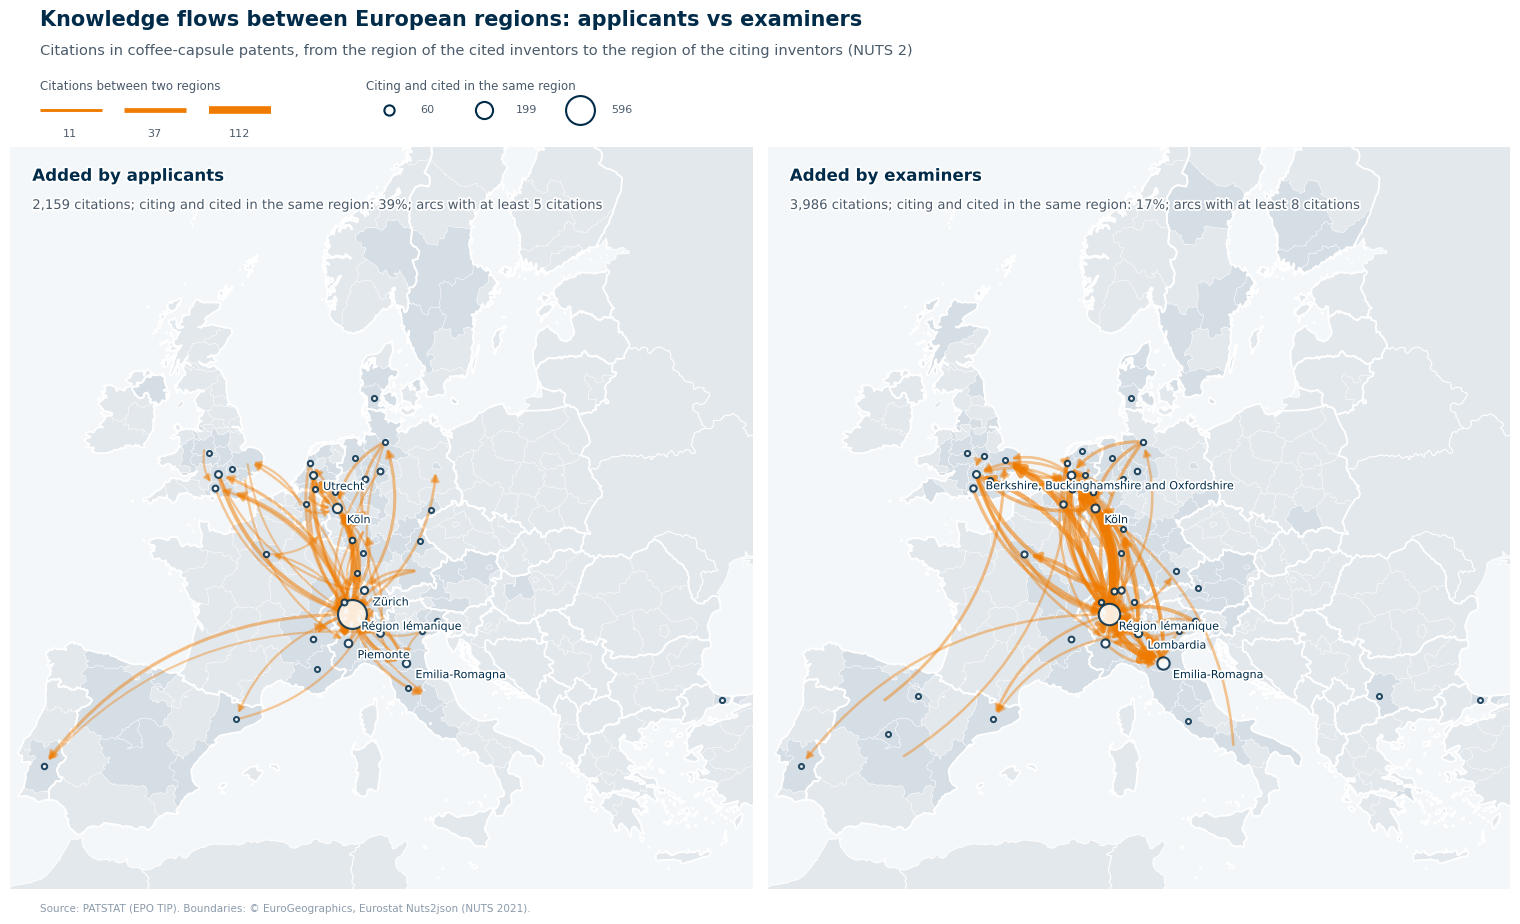

In [21]:
def draw_flows(ax, flows, points, colour=ORANGE, min_n=1, bend=0.25, top=None, top_inside=None, max_width=5):
    """Curved arrows between regions (width ~ citations) and circles for flows inside a region."""
    top = top or flows.n.max()
    top_inside = top_inside or top
    between = flows[(flows.nuts2_cited != flows.nuts2_citing) & (flows.n >= min_n)].sort_values("n")
    for f in between.itertuples():
        a, b = points[f.nuts2_cited], points[f.nuts2_citing]
        weight = np.sqrt(f.n / top)
        width = 0.5 + max_width * weight
        ax.add_patch(FancyArrowPatch(
            (a.x, a.y), (b.x, b.y), connectionstyle=f"arc3,rad={bend}",
            arrowstyle="-|>,head_length=0.45,head_width=0.25", mutation_scale=5 + 2.2 * width,
            linewidth=width, color=colour, alpha=0.25 + 0.6 * weight,
            shrinkA=3, shrinkB=5, zorder=4, capstyle="round"))
    inside = flows[flows.nuts2_cited == flows.nuts2_citing]
    for f in inside.itertuples():
        p = points[f.nuts2_cited]
        ax.scatter(p.x, p.y, s=circle_size(f.n, top_inside), facecolor="white", alpha=0.85, edgecolor=NAVY, linewidth=1.5, zorder=5)
    return top


def circle_size(n, top):
    return 12 + 420 * n / top


def flow_legend(fig, top, items=(("between two regions", ORANGE),), top_inside=None, max_width=5, x=0.02, width=0.75):
    """Under the subtitle: line widths for three reference values, and circle sizes."""
    lax = fig.add_axes([x, from_top(fig, 1.45), width, 0.6 / fig.get_figheight()])
    lax.axis("off")
    lax.set_xlim(0, 10 * width / 0.75)
    lax.set_ylim(0, 1)
    def refs_for(t):
        return sorted({max(1, round(t / 10)), max(1, round(t / 3)), int(t)})
    refs = refs_for(top)
    pos = 0.0
    for label, colour in items:
        lax.text(pos, 0.95, f"Citations {label}", fontsize=8.5, color=GREY, va="top")
        for i, v in enumerate(refs):
            w = 0.5 + max_width * np.sqrt(v / top)
            lax.plot([pos + 0.75 * i, pos + 0.75 * i + 0.55], [0.45, 0.45], color=colour, linewidth=w, solid_capstyle="butt")
            lax.text(pos + 0.75 * i + 0.27, 0.0, f"{v}", ha="center", fontsize=8, color=GREY)
        pos += 2.9
    if top_inside:
        lax.text(pos, 0.95, "Citing and cited in the same region", fontsize=8.5, color=GREY, va="top")
        for i, v in enumerate(refs_for(top_inside)):
            lax.scatter(pos + 0.2 + 0.85 * i, 0.45, s=circle_size(v, top_inside), facecolor="white", edgecolor=NAVY, linewidth=1.5)
            lax.text(pos + 0.48 + 0.85 * i, 0.45, f"{v}", ha="left", va="center", fontsize=8, color=GREY)


MAX_ARCS = 90        # at most 90 arcs per map, to keep it readable
names2 = nuts2.set_index("nuts_id").name

active = set()
for f in flows_by.values():
    active |= set(f.nuts2_cited) | set(f.nuts2_citing)
area = fit_area(active, nuts2, aspect=1.0)
# same scales on both maps: one for arcs, one for circles
peak = max(f.loc[f.nuts2_cited != f.nuts2_citing, "n"].max() for f in flows_by.values())
peak_inside = max(f.loc[f.nuts2_cited == f.nuts2_citing, "n"].max() for f in flows_by.values())

fig, axes = new_maps(area, n=2, width=15)
for ax, (origin, f) in zip(axes, flows_by.items()):
    nuts2.plot(ax=ax, color=LAND, edgecolor="white", linewidth=0.3)
    nuts2[nuts2.nuts_id.isin(set(f.nuts2_cited) | set(f.nuts2_citing))].plot(ax=ax, color=LAND_DATA, edgecolor="white", linewidth=0.3)
    nuts0.boundary.plot(ax=ax, color="white", linewidth=1.3)
    between = f[f.nuts2_cited != f.nuts2_citing]
    min_n = next(k for k in range(1, 10_000) if (between.n >= k).sum() <= MAX_ARCS)
    draw_flows(ax, f, points2, min_n=min_n, top=peak, top_inside=peak_inside)
    volume = f.groupby("nuts2_cited").n.sum().add(f.groupby("nuts2_citing").n.sum(), fill_value=0)
    for code_ in volume.nlargest(6).index:
        p = points2[code_]
        ax.annotate(names2[code_].split("/")[0], (p.x, p.y), xytext=(7, -11), textcoords="offset points",
                    fontsize=8, color=NAVY, path_effects=HALO, zorder=7)
    inside = f.loc[f.nuts2_cited == f.nuts2_citing, "n"].sum() / f.n.sum()
    shown = "" if min_n == 1 else f"; arcs with at least {min_n} citations"
    panel_title(ax, f"Added by {origin}s", f"{f.n.sum():,} citations; citing and cited in the same region: {inside:.0%}{shown}")

flow_legend(fig, peak, top_inside=peak_inside, width=0.5)
add_titles(fig, "Knowledge flows between European regions: applicants vs examiners",
           "Citations in coffee-capsule patents, from the region of the cited inventors to the region of the citing inventors (NUTS 2)")
plt.show()

### Zoom on the main hub

The region with most inventors is the **hub** of the sector. We ask two separate questions about it, one per map:

- **left, knowledge going out**: which regions **use** the hub's knowledge? An arrow from the hub to region X means that inventors in X cite patents invented in the hub.
- **right, knowledge coming in**: whose knowledge does the **hub use**? An arrow from region X to the hub means that inventors in the hub cite patents invented in X.

The thicker the arrow, the more citations; the number next to each region is the count. We use only applicant citations, as in the map above.

In [22]:
flows = flows_by["applicant"]
HUB = with_data.loc[with_data.applications.idxmax(), "nuts_id"]
hub_name = names2[HUB].split("/")[0]

out_of_hub = flows[(flows.nuts2_cited == HUB) & (flows.nuts2_citing != HUB)]   # others cite the hub
into_hub = flows[(flows.nuts2_citing == HUB) & (flows.nuts2_cited != HUB)]     # the hub cites others
same = flows.loc[(flows.nuts2_cited == HUB) & (flows.nuts2_citing == HUB), "n"].sum()

summary = pd.DataFrame({"cite the hub (out)": out_of_hub.set_index("nuts2_citing").n,
                        "cited by the hub (in)": into_hub.set_index("nuts2_cited").n}).fillna(0).astype(int)
summary.index = [f"{code_} {names2[code_].split('/')[0]}" for code_ in summary.index]
print(f"Hub: {HUB} {hub_name}. Citations with citing and cited inventors both in the hub: {same}")
summary.sort_values("cite the hub (out)", ascending=False).head(10)

Hub: CH01 Région lémanique. Citations with citing and cited inventors both in the hub: 596


,cite the hub (out),cited by the hub (in)
ITC1 Piemonte,50,6
ITC4 Lombardia,35,9
NL31 Utrecht,34,14
CH04 Zürich,32,2
ITH5 Emilia-Romagna,29,18
CH02 Espace Mittelland,28,35
"UKJ2 Surrey, East and West Sussex",19,0
CH03 Nordwestschweiz,17,6
DEA2 Köln,15,1
FRK2 Rhône-Alpes,15,3


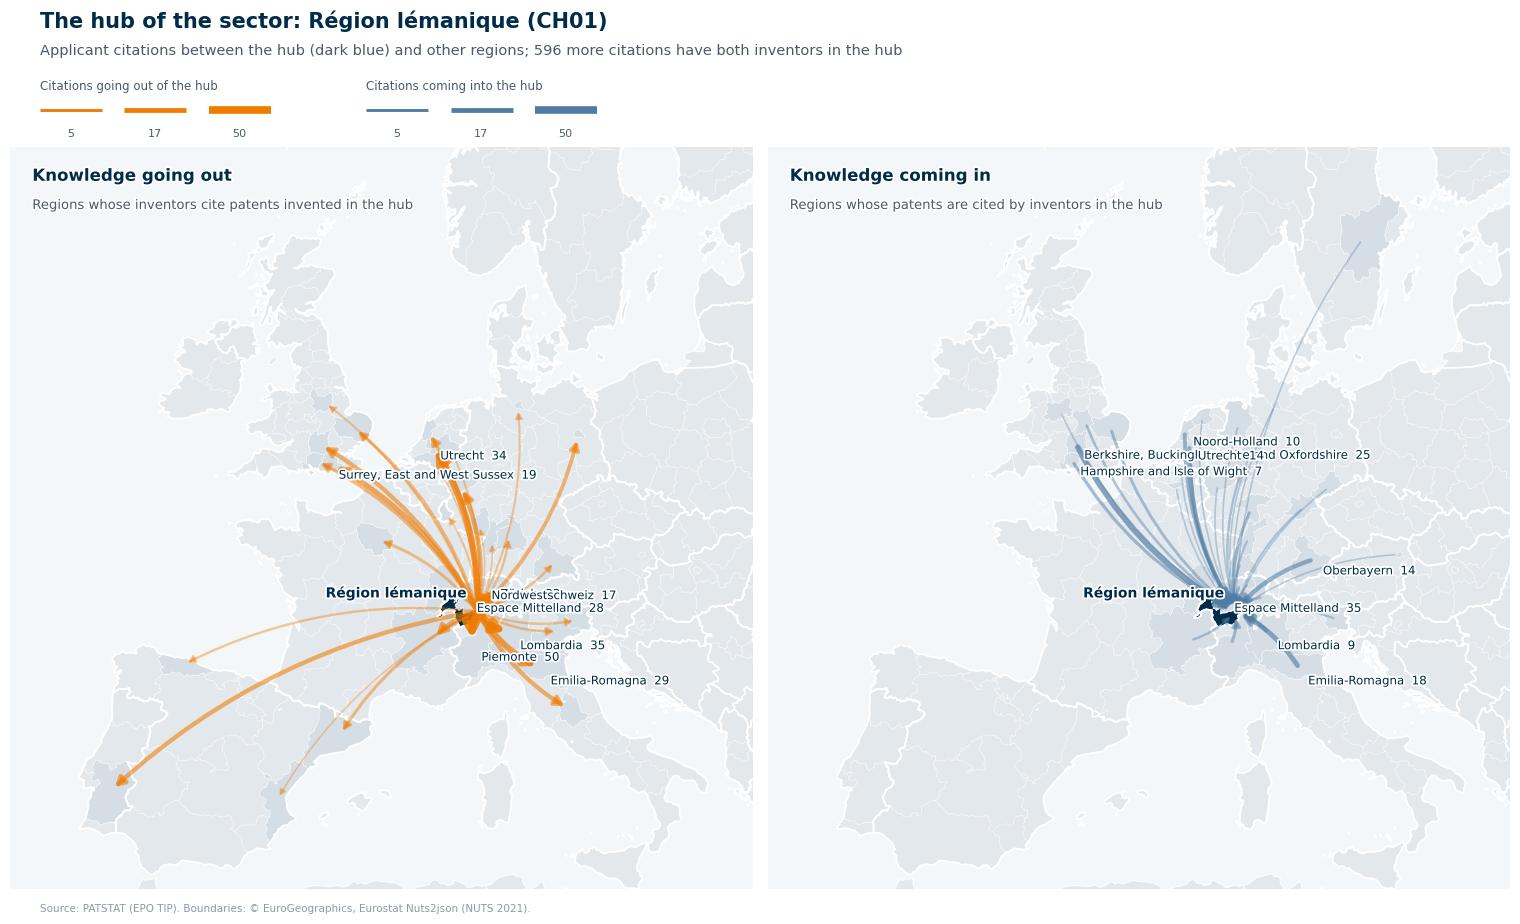

In [23]:
partners = set(out_of_hub.nuts2_citing) | set(into_hub.nuts2_cited)
peak = max(out_of_hub.n.max(), into_hub.n.max())
hub_point = points2[HUB]

fig, axes = new_maps(fit_area(partners | {HUB}, nuts2, aspect=1.0), n=2, width=15)
panels = [(out_of_hub, "nuts2_citing", ORANGE, "Knowledge going out", "Regions whose inventors cite patents invented in the hub"),
          (into_hub, "nuts2_cited", BLUE, "Knowledge coming in", "Regions whose patents are cited by inventors in the hub")]
for ax, (f, partner_col, colour, title, subtitle) in zip(axes, panels):
    nuts2.plot(ax=ax, color=LAND, edgecolor="white", linewidth=0.3)
    nuts2[nuts2.nuts_id.isin(f[partner_col])].plot(ax=ax, color=LAND_DATA, edgecolor="white", linewidth=0.3)
    nuts2[nuts2.nuts_id == HUB].plot(ax=ax, color=NAVY, edgecolor="white", linewidth=0.5)
    nuts0.boundary.plot(ax=ax, color="white", linewidth=1.3)
    draw_flows(ax, f, points2, colour=colour, bend=0.15, top=peak)
    for r in f.nlargest(8, "n").itertuples():                      # name and count of the main partners
        p = points2[getattr(r, partner_col)]
        ax.annotate(f"{names2[getattr(r, partner_col)].split('/')[0]}  {r.n}", (p.x, p.y), xytext=(6, -11),
                    textcoords="offset points", fontsize=8.5, color=NAVY, path_effects=HALO, zorder=7)
    ax.annotate(hub_name, (hub_point.x, hub_point.y), xytext=(-8, 10), textcoords="offset points", ha="right",
                fontsize=10, fontweight="bold", color=NAVY, path_effects=HALO, zorder=8)
    panel_title(ax, title, subtitle)

flow_legend(fig, peak, items=(("going out of the hub", ORANGE), ("coming into the hub", BLUE)), width=0.5)
add_titles(fig, f"The hub of the sector: {hub_name} ({HUB})",
           f"Applicant citations between the hub (dark blue) and other regions; {same} more citations have both inventors in the hub")
plt.show()

## 7. Are citations more local than expected?

For each citation we ask a simple question: **do the citing and the cited inventors live in the same place?** We ask it with three boundaries, from large to small:

- same **country**;
- same **NUTS 2** region (Piemonte, Lake Geneva region...);
- same **NUTS 3** region (Torino, Vaud...).

The share of citations that answer "yes" is the **localisation** of the citations at that boundary.

### Compared with what? The "by chance" benchmark

Inventors are concentrated in a few regions (map 1). So even if knowledge travelled freely, many citations would link two inventors of the same hub, just because most inventors are there. If 90% of the sector were in Vaud, about 90% of the citations would be "same region" without any local spillover. We need to know what share to expect **by chance**, and then see if the real share is higher.

The idea (from Jaffe, Trajtenberg and Henderson, 1993) is to ask, for each citation: *if this citation had been made by a random coffee-capsule application of the same year, instead of the real one, how likely would it be to come from the same region as the cited patent?*

The answer is simply the share of the same-year applications that are in the cited region. A worked example with three citations:

| Citation | Citing application filed in | Cited inventors live in | Applications of our sample filed that year | ... of which invented in that region | **By chance** | Citing inventors live in | **Same region?** |
|---|---|---|---|---|---|---|---|
| 1 | 2015 | Vaud | 100 | 30 | 30 / 100 = **30%** | Vaud | **yes** |
| 2 | 2015 | Torino | 100 | 5 | 5 / 100 = **5%** | Vaud | **no** |
| 3 | 2018 | Vaud | 80 | 20 | 20 / 80 = **25%** | Vaud | **yes** |

- **By chance** (grey bar) = average of the chance column = (30% + 5% + 25%) / 3 = **20%**.
- **Observed** (orange bar) = share of "yes" = 2 out of 3 = **67%**.

67% is far above 20%: the citing inventors are in the cited region much more often than the size of that region in the sector would explain.

Why the **same year**? Because the geography of the sector changes as firms enter and leave: a citation made in 2005 must be compared with the inventors active in 2005, not with those of 2020.

The next two cells do the same with our data: first one citation step by step, then eight citations (four in the same region, four not).

Reading the result is then easy:

- share of citations in the same region **close to chance**: the location of the inventors explains everything, nothing special happens locally;
- share **well above chance**: citations stay closer to home than the geography of the sector predicts. Knowledge circulates locally: this is the sign of local spillovers.

We do it separately for the citations added by **applicants** and by **examiners**. If local knowledge travels through people, applicant citations should be more local than examiner citations.

In [24]:
# One real citation, step by step: an applicant citation inside the hub, at NUTS 2 level
ex = cites[(cites.origin == "applicant") & (cites.nuts2_cited == HUB) & (cites.nuts2_citing == HUB)].iloc[0]
year, region = ex.citing_year, ex.nuts2_cited

same_year = ep_loc[ep_loc.appln_filing_year == year].nuts2.dropna()   # NUTS 2 of the same-year applications
in_region = (same_year == region).sum()

print(f"Citation: application {ex.appln_id} (filed {year}, inventors in {ex.nuts2_citing} {names2.get(ex.nuts2_citing, '')})")
print(f"          cites application {ex.cited_appln_id} (inventors in {region} {names2.get(region, '')})")
print(f"Applications of our sample filed in {year} with a known NUTS 2 region: {len(same_year)}")
print(f"  of which invented in {region}: {in_region}")
print(f"By chance: {in_region} / {len(same_year)} = {in_region / len(same_year):.0%}")
print(f"Same region in reality? {'yes' if ex.nuts2_citing == region else 'no'}")

Citation: application 41204 (filed 2008, inventors in CH01 Région lémanique)
          cites application 16105691 (inventors in CH01 Région lémanique)
Applications of our sample filed in 2008 with a known NUTS 2 region: 39
  of which invented in CH01: 5
By chance: 5 / 39 = 13%
Same region in reality? yes


In [25]:
# The same calculation for 8 citations (4 in the same region, 4 not), then the two averages
def chance_of(row, level="nuts2"):
    """Share of the sample's applications filed in the citing year that are invented in the cited region."""
    same_year = ep_loc[ep_loc.appln_filing_year == row.citing_year][level].dropna()
    return (same_year == row[f"{level}_cited"]).mean()


located = cites.dropna(subset=["nuts2_citing", "nuts2_cited"]).drop_duplicates("appln_id")   # one per citing application
same = located.nuts2_citing == located.nuts2_cited
example = pd.concat([located[same].head(4), located[~same].head(4)])
example["by chance"] = example.apply(chance_of, axis=1)
example["same region?"] = np.where(example.nuts2_citing == example.nuts2_cited, "yes", "no")

print(f"By chance (average of the column):  {example['by chance'].mean():.0%}")
print(f"Observed (share of 'yes'):          {(example['same region?'] == 'yes').mean():.0%}")
example[["appln_id", "citing_year", "nuts2_cited", "by chance", "nuts2_citing", "same region?"]] \
    .style.format({"by chance": "{:.0%}"}).hide(axis="index")

By chance (average of the column):  11%
Observed (share of 'yes'):          50%


appln_id,citing_year,nuts2_cited,by chance,nuts2_citing,same region?
41204,2008,CH01,13%,CH01,yes
142852,2003,DEA4,7%,DEA4,yes
15712573,2000,ITC4,33%,ITC4,yes
15814729,2001,CH01,25%,CH01,yes
20595,2008,DE60,0%,DE12,no
22259,2007,NL31,2%,CH01,no
52765,2005,CH01,4%,NL41,no
125627,2005,DE21,0%,NL32,no


The cell below does exactly this for **all** the citations, at the three boundaries, and separately for applicant and examiner citations. The function `same_year_shares` computes all the "by chance" shares at once (one per year and region) instead of one citation at a time; the result is the same.

In [26]:
LEVEL_NAMES = {"ctry": "Same country", "nuts2": "Same NUTS 2", "nuts3": "Same NUTS 3"}


def same_year_shares(level):
    """For each filing year, the share of the sample's applications in each region."""
    return (ep_loc.dropna(subset=[level])
                  .groupby("appln_filing_year")[level]
                  .value_counts(normalize=True))


def localisation(cites, level):
    """Share of citations with citing and cited inventors in the same region, and the share expected by chance."""
    d = cites.dropna(subset=[f"{level}_citing", f"{level}_cited"])
    same = d[f"{level}_citing"] == d[f"{level}_cited"]
    key = pd.MultiIndex.from_arrays([d.citing_year, d[f"{level}_cited"]])
    chance = same_year_shares(level).reindex(key).fillna(0)
    return len(d), same.mean(), chance.mean()


rows = {}
for level in LEVELS:
    n_app, app, chance_app = localisation(cites[cites.origin == "applicant"], level)
    n_exa, exa, chance_exa = localisation(cites[cites.origin == "examiner"], level)
    rows[LEVEL_NAMES[level]] = {"applicant citations": app, "examiner citations": exa,
                                "by chance": chance_app, "by chance (examiner citations)": chance_exa,
                                "applicant citations used": n_app, "examiner citations used": n_exa}
local = pd.DataFrame(rows).T

for level, r in local.iterrows():
    print(f"{level}: applicant citations {r['applicant citations']:.0%}, "
          f"examiner citations {r['examiner citations']:.0%}, by chance {r['by chance']:.0%}")

local.style.format({"applicant citations": "{:.0%}", "examiner citations": "{:.0%}", "by chance": "{:.0%}",
                    "by chance (examiner citations)": "{:.0%}",
                    "applicant citations used": "{:,.0f}", "examiner citations used": "{:,.0f}"})

Same country: applicant citations 43%, examiner citations 26%, by chance 18%
Same NUTS 2: applicant citations 39%, examiner citations 17%, by chance 12%
Same NUTS 3: applicant citations 37%, examiner citations 16%, by chance 12%


,applicant citations,examiner citations,by chance,by chance (examiner citations),applicant citations used,examiner citations used
Same country,43%,26%,18%,15%,"3,118","6,776"
Same NUTS 2,39%,17%,12%,9%,"2,159","3,986"
Same NUTS 3,37%,16%,12%,8%,"2,138","3,948"


`by chance` is computed on the applicant citations, as in section 8; the column next to it does the same for the examiner citations (each set of citations has its own years and cited regions, so the two benchmarks differ a little).

The last two columns count the citations used at each boundary: only those where we know where both inventors live. There are more at the country level, because the country is known for every inventor, also outside Europe; at NUTS 2 and NUTS 3 we only keep pairs of European inventors. NUTS 2 and NUTS 3 use (almost) the same citations, because a NUTS 3 code always contains its NUTS 2 code.

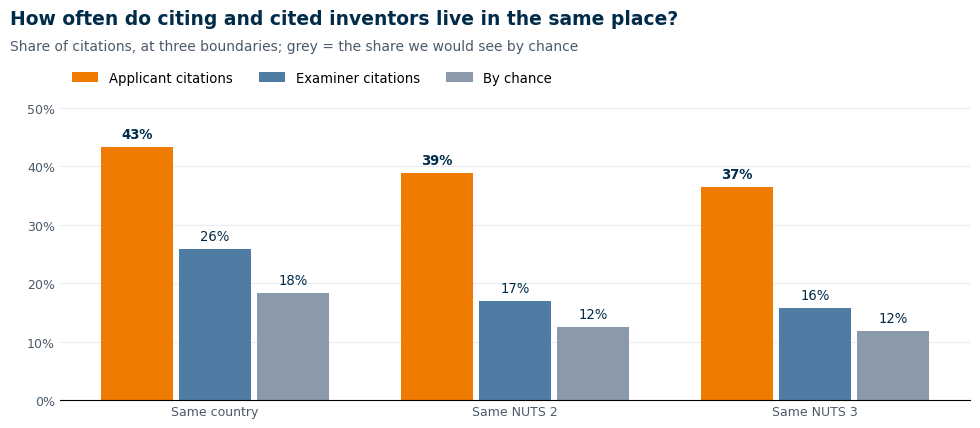

In [27]:
series = [("applicant citations", ORANGE), ("examiner citations", BLUE), ("by chance", MID)]
x = np.arange(len(local))
width = 0.26

fig, ax = plt.subplots(figsize=(10, 4.6))
fig.subplots_adjust(top=0.78, bottom=0.12, left=0.07, right=0.98)
for k, (col, colour) in enumerate(series):
    bars = ax.bar(x + (k - 1) * width, local[col], width=width * 0.92, color=colour, label=col.capitalize())
    for b, v in zip(bars, local[col]):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.0%}", ha="center", va="bottom", fontsize=9.5,
                color=NAVY, fontweight="bold" if col == "applicant citations" else "normal")
ax.set_xticks(x)
ax.set_xticklabels(local.index, fontsize=10.5, color=NAVY)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_ylim(0, local[[c for c, _ in series]].to_numpy().max() * 1.2)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=3, frameon=False, fontsize=9.5)
ax.grid(axis="y", color="#E8ECF0")
ax.set_axisbelow(True)
ax.tick_params(length=0, colors=GREY, labelsize=9)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
fig.text(0.02, 0.97, "How often do citing and cited inventors live in the same place?", fontsize=13.5,
         fontweight="bold", color=NAVY, va="top")
fig.text(0.02, 0.905, "Share of citations, at three boundaries; grey = the share we would see by chance",
         fontsize=10, color=GREY, va="top")
plt.show()

**How to read it.** In each group, compare the orange bar with the grey one. The further the orange bar is above the grey one, the more knowledge circulates locally. Then compare orange with blue: if applicant citations are more local than examiner citations, the local flows really pass through the inventors, not through the search databases of the patent office.

## 8. Does knowledge fade as we move away?

Regions have borders, and borders are arbitrary: two inventors 5 km apart can sit in two regions. So we now look at **distance** instead, using the citations added by applicants.

For each citation with both inventors located in a European NUTS 3 region, we measure the distance between the two regions in km, and put it in a band: same NUTS 3, less than 100 km, 100-300 km, 300-600 km, more than 600 km. Then we compare, band by band:

- **orange**: the share of citations at that distance;
- **grey**: the share we would see by chance.

"By chance" works as in section 7, with distance bands instead of a yes/no. Take a 2015 citation to a patent invented in Vaud, and measure how far each of the 100 applications of 2015 is from Vaud: say 30 are in Vaud itself, 10 within 100 km (Geneva, Fribourg), 25 at 100-300 km (Zürich, Torino), 20 at 300-600 km and 15 farther. A random 2015 application would then fall 30% in "same NUTS 3", 10% in "< 100 km", 25% in "100-300 km", and so on. We do this for every citation and average each band: those are the grey bars.

**If knowledge fades with distance**, the orange bars are above the grey ones in the closest bands (citations happen near the cited invention more often than chance), and below them in the farthest bands.

2,138 applicant citations with both inventors in a NUTS 3 region; median distance 175 km


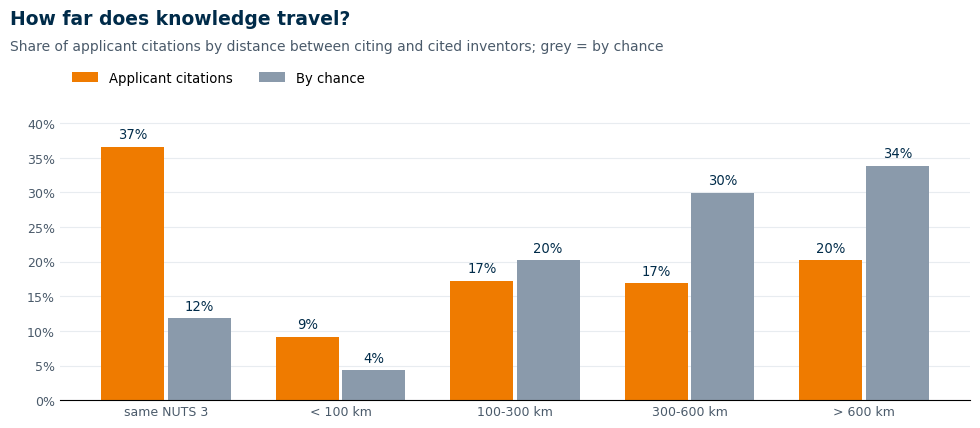

In [28]:
points3 = nuts3.set_index("nuts_id").representative_point()
xy = pd.DataFrame({"x": points3.x, "y": points3.y})

BANDS = [-1, 1, 100, 300, 600, 10_000]
BAND_LABELS = ["same NUTS 3", "< 100 km", "100-300 km", "300-600 km", "> 600 km"]


def km(a, b):
    """Distance in km between two lists of NUTS 3 codes (EPSG:3035 is in metres)."""
    a, b = xy.loc[a], xy.loc[b]
    return np.hypot(a.x.to_numpy() - b.x.to_numpy(), a.y.to_numpy() - b.y.to_numpy()) / 1000


# Observed: the distance of each applicant citation
d = cites[cites.origin == "applicant"].dropna(subset=["nuts3_citing", "nuts3_cited"])
d = d[d.nuts3_citing.isin(xy.index) & d.nuts3_cited.isin(xy.index)].copy()
d["km"] = km(d.nuts3_citing, d.nuts3_cited)
observed = pd.cut(d.km, BANDS, labels=BAND_LABELS).value_counts(normalize=True).reindex(BAND_LABELS)

# By chance: for each citation, the distances from the cited region to all same-year applications of the sample
pool = ep_loc.dropna(subset=["nuts3"])
pool = pool[pool.nuts3.isin(xy.index)]
shares = {}
for (year, region), _ in d.groupby(["citing_year", "nuts3_cited"]):
    others = pool[pool.appln_filing_year == year].nuts3
    if len(others):
        dist = km([region] * len(others), others)
        shares[(year, region)] = pd.cut(pd.Series(dist), BANDS, labels=BAND_LABELS).value_counts(normalize=True)
per_citation = [shares[k] for k in zip(d.citing_year, d.nuts3_cited) if k in shares]
chance = pd.concat(per_citation, axis=1).mean(axis=1).reindex(BAND_LABELS)

decay = pd.DataFrame({"citations": observed, "by chance": chance})
print(f"{len(d):,} applicant citations with both inventors in a NUTS 3 region; median distance {d.km.median():,.0f} km")

x = np.arange(len(decay))
fig, ax = plt.subplots(figsize=(10, 4.6))
fig.subplots_adjust(top=0.78, bottom=0.12, left=0.07, right=0.98)
for k, (col, colour) in enumerate([("citations", ORANGE), ("by chance", MID)]):
    bars = ax.bar(x + (k - 0.5) * 0.38, decay[col], width=0.36, color=colour,
                  label="Applicant citations" if col == "citations" else "By chance")
    for b, v in zip(bars, decay[col]):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.008, f"{v:.0%}", ha="center", va="bottom", fontsize=9.5, color=NAVY)
ax.set_xticks(x)
ax.set_xticklabels(decay.index, fontsize=10.5, color=NAVY)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_ylim(0, decay.to_numpy().max() * 1.2)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, frameon=False, fontsize=9.5)
ax.grid(axis="y", color="#E8ECF0")
ax.set_axisbelow(True)
ax.tick_params(length=0, colors=GREY, labelsize=9)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
fig.text(0.02, 0.97, "How far does knowledge travel?", fontsize=13.5, fontweight="bold", color=NAVY, va="top")
fig.text(0.02, 0.905, "Share of applicant citations by distance between citing and cited inventors; grey = by chance",
         fontsize=10, color=GREY, va="top")
plt.show()

The cell below sums up the chart in two lines: the citations made close to the cited invention (within 100 km) and far from it (more than 600 km), each compared with chance.

In [29]:
near = decay.loc[["same NUTS 3", "< 100 km"]].sum()
far = decay.loc["> 600 km"]
print(f"Within 100 km:  {near['citations']:.0%} of the citations, {near['by chance']:.0%} by chance")
print(f"Beyond 600 km:  {far['citations']:.0%} of the citations, {far['by chance']:.0%} by chance")
if near["citations"] > near["by chance"] and far["citations"] < far["by chance"]:
    print("Knowledge fades with distance: citations happen near the cited invention more often than chance, far from it less often.")
else:
    print("No clear fading: in this sample distance does not change much where citations happen.")

Within 100 km:  46% of the citations, 16% by chance
Beyond 600 km:  20% of the citations, 34% by chance
Knowledge fades with distance: citations happen near the cited invention more often than chance, far from it less often.


## 9. How to use this in your PW

Change `CPC_PREFIX` to the CPC code of your sector and run the notebook again. Everything else adapts: the maps zoom on your sector's regions, the hub is your sector's first region.

What you can take for the report:

- **The geography of your field.** Map 1 and the ranking describe where the R&D of your sector is done: which countries and regions, how concentrated it is, which hub dominates. Combine it with the applicant table of section 2 to explain *why* (one large firm, a cluster of small firms, a university). This is useful even if you do nothing else with citations: it is the "where" of your sector's landscape.
- **Owners vs inventors.** The applicant vs inventor table shows whether the main firms invent where they are registered, or run R&D centres elsewhere.

Two cautions. With a small sector some numbers rest on few citations: always report how many citations a share is based on, and do not read much into shares computed on a few dozen citations. And the maps cover Europe: if your sector is mostly invented in the US or Asia, say so (the country table of section 3) and use the country level.

## 10. What the test can and cannot say

- **Flows, not spillovers.** A local citation is a local flow of knowledge. It is a spillover only if the citing firm did not pay for it, and patents do not say. Localisation is a *proxy*: knowledge that is bought (licences, contracts) has no reason to stay local, while knowledge that leaks through people, meetings and job changes does.
- **Self-citations.** A firm citing its own earlier patents is a flow inside the firm, not a spillover, and it is very local. Removing them (same applicant on both sides) is the first refinement to try.
- **Examiner citations** are noise for this question (section 7). With US patents the mix of applicant and examiner citations is different again, which is why we stay on EP.
- **Address ≠ workplace.** NUTS codes come from the inventor's home address. Commuters across a regional border look non-local.
- **Coverage.** Inventors outside Europe have no NUTS code, so the NUTS tests only use European pairs. For larger studies, the OECD **REGPAT** database gives regions for EPO and PCT inventors and applicants, including regions outside Europe.
